# Application of QMCCBO: A two-dimensional data-driven model for traffic flow in highways

### Data Set: Vehicle Trajectory Dataset from Drone Videos by Moritz Berghausa, Serge Lambertya, Jörg Ehlersa, Eszter Kallóa, Markus Oeser

# On-ramp data set

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch
import os

df = pd.read_csv("data/DroneDataEastToWestCSV_220725.csv")

In [25]:
df.head()

,tseconds,ttimestamp,ID,VehicleCategory,Length,Width,x,y,vx,vy,ax,ay
0,4292.0,2021-09-06 07:11:32.0,81020006,Motorcycle,2.456,0.776,1383.553092,0.928971,22.799909,-0.079986,0.740688,0.007672
1,4292.1,2021-09-06 07:11:32.1,81020006,Motorcycle,2.456,0.776,1385.844932,0.921186,22.866907,-0.079260,0.732071,0.007625
2,4292.2,2021-09-06 07:11:32.2,81020006,Motorcycle,2.456,0.776,1388.137405,0.913400,22.933929,-0.078535,0.723438,0.007577
3,4292.3,2021-09-06 07:11:32.3,81020006,Motorcycle,2.456,0.776,1390.431644,0.905610,23.001016,-0.077809,0.714751,0.007530
4,4292.4,2021-09-06 07:11:32.4,81020006,Motorcycle,2.456,0.776,1392.729054,0.897816,23.068205,-0.077083,0.705958,0.007482


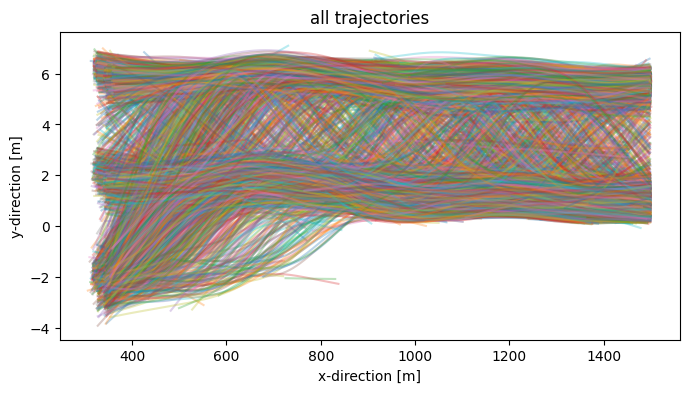

In [26]:
plt.figure(figsize=(8,4))

for vehicle_id, group in df.groupby("ID"):
    plt.plot(group["x"], group["y"], alpha=0.3)

plt.xlabel("x-direction [m]")
plt.ylabel("y-direction [m]")
plt.title("all trajectories")
plt.savefig("images/all_trajectories_onramp.png", dpi=300, bbox_inches="tight")
plt.show()

### fundamental diagrams

In [27]:
# transform velocity [m/s] to [km/h]
df["vx_kmh"] = df["vx"] * 3.6  
df["vy_kmh"] = df["vy"] * 3.6 

# determine density
L = df["x"].max() - df["x"].min()  # road length [m]
df["t_bin"] = np.floor(df["tseconds"])
N = df.groupby("t_bin")["ID"].nunique()
rho = N / (L / 1000)  # \tilde{rho}(t_k): density [vehicle/km] per time 

# determine average velocity and fluxes
ux_kmh = df.groupby("t_bin")["vx_kmh"].mean()  # \tilde{u}^x(t_k): average velocity [km/h] in x-direction per time 
uy_kmh = df.groupby("t_bin")["vy_kmh"].mean()  # \tilde{u}^y(t_k): aberage velocity [km/h] in y-direction per time
qx = rho * ux_kmh  # \tilde{q}^x(t_k): flux [vehicle/h] in x-direction per time 
qy = rho * uy_kmh  # \tilde{q}^y(t_k): flux [vehicle/h] in x-direction per time 

# determine moving mean of densitiy, flux and average velocity
window_value = 60*3  # corresponds to 180 seconds
rho_data = rho.rolling(window=window_value, min_periods=window_value).mean()
qx_data = qx.rolling(window=window_value, min_periods=window_value).mean()
qy_data = qy.rolling(window=window_value, min_periods=window_value).mean()

# neglect non-numerical values
mask = (rho_data.notna() & qx_data.notna() & qy_data.notna())  
rho_data = rho_data[mask]
qx_data = qx_data[mask]
qy_data = qy_data[mask]
ux_data = qx_data / rho_data 
uy_data = qy_data / rho_data

# transform to torch-tensor for (QMC)CBO application
rho_torch = torch.tensor(rho_data.to_numpy(), dtype=torch.float32)
qx_torch = torch.tensor(qx_data.to_numpy(), dtype=torch.float32)
qy_torch = torch.tensor(qy_data.to_numpy(), dtype=torch.float32)
ux_torch = qx_torch / rho_torch
uy_torch = qy_torch / rho_torch

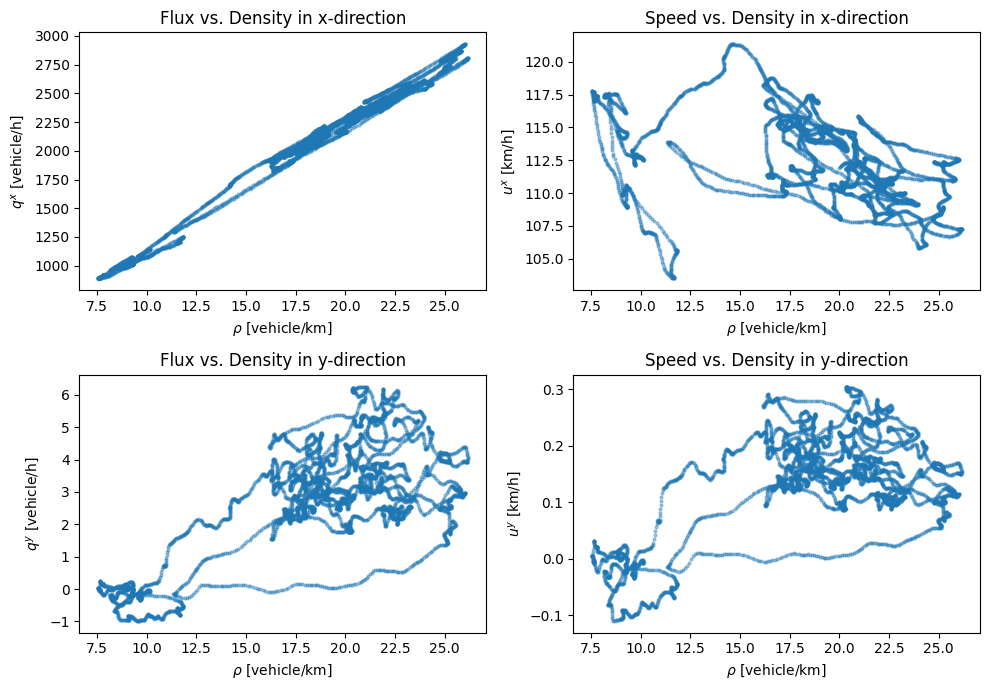

In [28]:
# plotting fundamental diagrams
fig, ax = plt.subplots(2, 2, figsize=(10,7))

# Flux x-direction
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=0.4)
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")

# Speed x-direction
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=0.4)
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=0.4)
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=0.4)
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")

plt.tight_layout()
plt.savefig("images/fundamental_diagrams_onramp.png", dpi=300, bbox_inches="tight")
plt.show()

### Model and objective functions

In [29]:
number_lanes = 2  # number of lanes without off-ramp
rho_max = number_lanes / 7.5 * 1000  # maxmial density [vehicle/km]

# Model functions 

# Scipy optimization
# INPUT: - alpha (scalar): alpha parameter
#        - lam (scalar): lambda parameter
#        - p (scalar): p parameter
#        - rho (1xM numpy-vector): density rho for any obersvation (data point)
# OUTPUT: - prediction (1xM numpy-vector): approximated flux for model parameter combination and observed data point (column)
def qx_model_numpy(rho, alpha, lam, p):

    d1 = np.sqrt(1 + (lam*p)**2)
    d2 = np.sqrt(1 + (lam*(1-p))**2)
    d3 = lam*(rho/rho_max - p)
    return alpha*(d1 + (d2-d1)*(rho/rho_max) - np.sqrt(1 + d3**2))

def qy_model_numpy(rho, alpha, lam, p):

    d1 = np.sqrt(1 + (lam*p)**2)
    d2 = np.sqrt(1 + (lam*(1-p))**2)
    d3 = lam*(rho/rho_max - p)
    return alpha*(d1 + (d2-d1)*(rho/rho_max) - np.sqrt(1 + d3**2))

# (QMC)CBO 
# INPUT: - alpha (Nx1 torch-tensor): alpha parameters for all particles
#        - lam (Nx1 torch-tensor): lambda parameters for all particles
#        - p (Nx1 torch-tensor): p parameters for all particles
#        - rho (1xM torch-tensor): density rho for any obersvation (data point)
# OUTPUT: - prediction (NxM torch-tensor): approximated flux for any model parameter combination (row) and observed data point (column)
def qx_model_torch(alpha, lam, p, rho):

    d1 = torch.sqrt(1 + (lam*p)**2)  # torch-tensor size Nx1
    d2 = torch.sqrt(1 + (lam*(1-p))**2)  # torch-tensor size Nx1
    d3 = lam*(rho/rho_max - p)  # broadcasting: Nx1 * (1xM/1x1 - Nx1) = NxM
    return alpha * (d1 + (d2-d1)*(rho/rho_max) - torch.sqrt(1 + d3**2))  # broadcasting: Nx1 * ( Nx1 + Nx1 * 1xM) - NxM )

def qy_model_torch(alpha, lam, p, rho):

    d1 = torch.sqrt(1 + (lam*p)**2)  # torch-tensor size Nx1
    d2 = torch.sqrt(1 + (lam*(1-p))**2)  # torch-tensor size Nx1
    d3 = lam*(rho/rho_max - p)  # broadcasting: Nx1 * (1xM/1x1 - Nx1) = NxM
    return alpha * (d1 + (d2-d1)*(rho/rho_max) - torch.sqrt(1 + d3**2))  # broadcasting: Nx1 * ( Nx1 + Nx1 * 1xM) - NxM )



# Objective functions

# Scipy optimization
# INPUT : - theta ((3) numpy-vector): describing three modelparameters
# OUTPUT : - scalar: describes the loss for theta model parameters
def objective_x_numpy(theta):
    alpha, lam, p = theta
    q_fit = qx_model_numpy(rho_data, alpha, lam, p)
    return np.sum((qx_data - q_fit)**2)

def objective_y_numpy(theta):
    alpha, lam, p = theta
    q_fit = qy_model_numpy(rho_data, alpha, lam, p)
    return np.sum((qy_data - q_fit)**2)

# (QMC)CBO
# INPUT : - V ((N x 3)-torch-matrix): describing three modelparameters for each particle/model parameter configuration
# OUTPUT : - V_prime ((1xN)-torch-matrix): describes the loss for each model parameter configuration
def objective_x_torch(V):
    # Extract model parameters from V columnwise to torch tensor of size 1xM
    alpha = V[:, 0:1]
    lam = V[:, 1:2]
    p = V[:, 2:3]

    # transforms data into torch tensor of size 1xM to match model parameters dimension
    rho = rho_torch[None, :]
    qx = qx_torch[None, :]

    qx_prediction = qx_model_torch(alpha, lam, p, rho)
    return torch.sum((qx_prediction - qx)**2, dim=1)

def objective_y_torch(V):
    # Extract model parameters from V columnwise to torch tensor of size 1xM
    alpha = V[:, 0:1]
    lam = V[:, 1:2]
    p = V[:, 2:3]

    # transforms data into torch tensor of size 1xM to match model parameters dimension
    rho = rho_torch[None, :]
    qy = qy_torch[None, :]

    qy_prediction = qy_model_torch(alpha, lam, p, rho)
    return torch.sum((qy_prediction - qy)**2, dim=1)

### Data Fitting

In [30]:
from scipy.optimize import minimize
from scipy.optimize import differential_evolution
import optimization.CBO as CBO
import optimization.QMCCBO_base2 as QMCCBO_base2
from torch.distributions import Uniform
from IPython.display import display, Math
import time

Nelder-Mead (Simplex)

In [ ]:
# initial simplex
initial_simplex = np.array([
    [100, 1, -20],   # initial guess
    [300, 1, -20],   # variation in alpha
    [100, -200, -20],   # variation in lambda
    [100, 1, 400]    # variation in p
])
function_value = 1e-6

# Model prediction x-direction
start_time_x = time.perf_counter()
result_x_simplex = minimize(objective_x_numpy, x0=initial_simplex[0], method="Nelder-Mead", options={"initial_simplex": initial_simplex, "fatol": function_value,  "maxfev": 2048,  "maxiter": 1300})
end_time_x = time.perf_counter()
time_x_simplex = end_time_x - start_time_x
alpha_x_simplex, lambda_x_simplex, p_x_simplex = result_x_simplex.x

print("Iterations:", result_x_simplex.nit)
print("Function evaluations:", result_x_simplex.nfev)
print("Success:", result_x_simplex.success)
print("Message:", result_x_simplex.message)

# Model prediction y-direction
start_time_y = time.perf_counter()
result_y_simplex = minimize(objective_y_numpy, x0=initial_simplex[0], method="Nelder-Mead", options={"initial_simplex": initial_simplex, "fatol": function_value,  "maxfev": 2048,  "maxiter": 1300})
end_time_y = time.perf_counter()
time_y_simplex = end_time_y - start_time_y
alpha_y_simplex, lambda_y_simplex, p_y_simplex = result_y_simplex.x

print("Iterations:", result_y_simplex.nit)
print("Function evaluations:", result_y_simplex.nfev)
print("Success:", result_y_simplex.success)
print("Message:", result_y_simplex.message)

Iterations: 3
Function evaluations: 14
Success: True
Message: Optimization terminated successfully.
Iterations: 68
Function evaluations: 141
Success: True
Message: Optimization terminated successfully.


In [32]:
display(Math(
    rf"\text{{Model parameters in x-direction with Nelder-Mead}}:\;"
    rf"\alpha^x = {alpha_x_simplex:.4f},\;"
    rf"\lambda^x = {lambda_x_simplex:.4f},\;"
    rf"p^x = {p_x_simplex:.4f}\;"
    rf"\text{{time}} = {time_x_simplex:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {result_x_simplex.nfev}"
))



display(Math(
    rf"\text{{Model parameters in y-direction with Nelder-Mead}}:\;"
    rf"\alpha^y = {alpha_y_simplex:.4f},\;"
    rf"\lambda^y = {lambda_y_simplex:.4f},\;"
    rf"p^y = {p_y_simplex:.4f}\;"
    rf"\text{{time}} = {time_y_simplex:.2f}\,\text{{s}}\;"
    rf"\text{{function evalutions}} = {result_y_simplex.nfev}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

L-BFGS-B

In [ ]:
# Model prediction x-direction
start_time_x = time.perf_counter()
result_x_lbfgs = minimize(objective_x_numpy, x0=[10, 10, 10], method="L-BFGS-B", bounds=[(-500,500), (-500,500), (-500,500)], options={"maxiter": 400, "maxfun": 2048, "ftol": function_value, "maxcor": 10})
end_time_x = time.perf_counter()
time_x_lbfgs = end_time_x - start_time_x
alpha_x_lbfgs, lambda_x_lbfgs, p_x_lbfgs = result_x_lbfgs.x

print("Iterations:", result_x_lbfgs.nit)
print("Function evaluations:", result_x_lbfgs.nfev)
print("Success:", result_x_lbfgs.success)
print("Message:", result_x_lbfgs.message)

# Model prediction y-direction
start_time_y = time.perf_counter()
result_y_lbfgs = minimize(objective_y_numpy, x0=[10, 10, 10], method="L-BFGS-B", bounds=[(-500,500), (-500,500), (-500,500)], options={"maxiter": 400, "maxfun": 2048, "ftol": function_value, "maxcor": 10})
end_time_y = time.perf_counter()
time_y_lbfgs = end_time_y - start_time_y
alpha_y_lbfgs, lambda_y_lbfgs, p_y_lbfgs = result_y_lbfgs.x

print("Iterations:", result_y_lbfgs.nit)
print("Function evaluations:", result_y_lbfgs.nfev)
print("Success:", result_y_lbfgs.success)
print("Message:", result_y_lbfgs.message)

Iterations: 21
Function evaluations: 180
Success: True
Message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterations: 4
Function evaluations: 96
Success: True
Message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH


In [34]:
display(Math(
    rf"\text{{Model parameters in x-direction with L-BFGS-R}}:\;"
    rf"\alpha^x = {alpha_x_lbfgs:.4f},\;"
    rf"\lambda^x = {lambda_x_lbfgs:.4f},\;"
    rf"p^x = {p_x_lbfgs:.4f}\;"
    rf"\text{{time}} = {time_x_lbfgs:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {result_x_lbfgs.nfev}"
))

display(Math(
    rf"\text{{Model parameters in y-direction with L-BFGS-R}}:\;"
    rf"\alpha^y = {alpha_y_lbfgs:.4f},\;"
    rf"\lambda^y = {lambda_y_lbfgs:.4f},\;"
    rf"p^y = {p_y_lbfgs:.4f}\;"
    rf"\text{{time}} = {time_y_lbfgs:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {result_y_lbfgs.nfev}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Differential Evolution

In [ ]:
# Model prediction x-direction
start_time_x = time.perf_counter()
result_x_de = differential_evolution(objective_x_numpy, bounds=[(-500,500), (-500,500), (-500,500)], tol=function_value, maxiter=44, init='random', updating='deferred', polish=False) #fev_max = 1980 = 15 * 3 * 2 * 11 = popsize * number params * 2 * max_iter)
end_time_x = time.perf_counter()
time_x_de = end_time_x - start_time_x
alpha_x_de, lambda_x_de, p_x_de = result_x_de.x

print("Iterations:", result_x_de.nit)
print("Function evaluations:", result_x_de.nfev)
print("Success:", result_x_de.success)
print("Message:", result_x_de.message)

# Model prediction y-direction
start_time_y = time.perf_counter()
result_y_de = differential_evolution(objective_y_numpy, bounds=[(-500,500), (-500,500), (-500,500)], tol=function_value, maxiter=44, init='random', updating='deferred', polish=False)
end_time_y = time.perf_counter()
time_y_de = end_time_y - start_time_y
alpha_y_de, lambda_y_de, p_y_de = result_y_de.x

print("Iterations:", result_y_de.nit)
print("Function evaluations:", result_y_de.nfev)
print("Success:", result_y_de.success)
print("Message:", result_y_de.message)

Iterations: 22
Function evaluations: 1083
Success: False
Message: Maximum number of iterations has been exceeded.
Iterations: 1
Function evaluations: 170
Success: True
Message: Optimization terminated successfully.


In [36]:
display(Math(
    rf"\text{{Model parameters in x-direction with Differential Evolution}}:\;"
    rf"\alpha^x = {alpha_x_de:.4f},\;"
    rf"\lambda^x = {lambda_x_de:.4f},\;"
    rf"p^x = {p_x_de:.4f}\;"
    rf"\text{{time}} = {time_x_de:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {result_x_de.nfev}"
))

display(Math(
    rf"\text{{Model parameters in y-direction with Differential Evolution}}:\;"
    rf"\alpha^y = {alpha_y_de:.4f},\;"
    rf"\lambda^y = {lambda_y_de:.4f},\;"
    rf"p^y = {p_y_de:.4f}\;"
    rf"\text{{time}} = {time_y_de:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {result_y_de.nfev}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

CBO

In [37]:
# set input for (QMC)CBO
dimensionality = 3  # dimension of the problem
n_particles = 11  # number of agents 2^n_particles
dt = 0.05  # step size of discretization
l = 1  # lambda (drift paramter)
sigma = 1
alpha = 100  # alpha (consensus weight)
n_particles_batches = 1  # batch size of each batch
epochs = 100  # number of iteration od SDE solution scheme (M)
batch_size = None
time_horizon = None

In [38]:
# set input for cbo
initial_distribution = Uniform(-500,500)  # initial distribution function
SDE_method = 'Euler_Maruyama'  # SDE solution scheme
anisotropic = False  # anisotropic CBO

# Model prediction x-direction
start_time_x = time.perf_counter()
result_x_CBO = CBO.minimize(
        objective_x_torch, dimensionality, 2**n_particles, initial_distribution, dt, l, sigma, 
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
end_time_x = time.perf_counter()
time_x_CBO = end_time_x - start_time_x

start_time_y = time.perf_counter()
result_y_CBO = CBO.minimize(
        objective_y_torch, dimensionality, 2**n_particles, initial_distribution, dt, l, sigma, 
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
end_time_y = time.perf_counter()
time_y_CBO = end_time_y - start_time_y

alpha_x_CBO, lambda_x_CBO, p_x_CBO = result_x_CBO.numpy()
alpha_y_CBO, lambda_y_CBO, p_y_CBO = result_y_CBO.numpy()

In [39]:
display(Math(
    rf"\text{{Model parameters in x-direction with Differential Evolution}}:\;"
    rf"\alpha^x = {alpha_x_CBO:.4f},\;"
    rf"\lambda^x = {lambda_x_CBO:.4f},\;"
    rf"p^x = {p_x_CBO:.4f}\;"
    rf"\text{{time}} = {time_x_CBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {2 ** n_particles}"
))

display(Math(
    rf"\text{{Model parameters in y-direction with Differential Evolution}}:\;"
    rf"\alpha^y = {alpha_y_CBO:.4f},\;"
    rf"\lambda^y = {lambda_y_CBO:.4f},\;"
    rf"p^y = {p_y_CBO:.4f}\;"
    rf"\text{{time}} = {time_y_CBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {2 ** n_particles}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

QMCCBO

In [40]:
# set input for QMCCBO
K = 500  # radius of cube
x_est = np.array([0,0,0])  # estimation of minimizer
ODE_method = 'Euler'  # SDE solution scheme 
theta = 0

# Model prediction x-direction
start_time_x = time.perf_counter()
result_x_QMCCBO = QMCCBO_base2.minimize(
        objective_x_torch, dimensionality, n_particles, K, x_est, dt, l, alpha, 
        ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
end_time_x = time.perf_counter()
time_x_QMCCBO = end_time_x - start_time_x

# Model prediction y-direction
start_time_y = time.perf_counter()
result_y_QMCCBO = QMCCBO_base2.minimize(
        objective_y_torch, dimensionality, n_particles, K, x_est, dt, l, alpha, 
        ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
end_time_y = time.perf_counter()
time_y_QMCCBO = end_time_y - start_time_y

alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO = result_x_QMCCBO.numpy()
alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO = result_y_QMCCBO.numpy()

In [41]:
display(Math(
    rf"\text{{Model parameters in x-direction with CBO}}:\;"
    rf"\alpha^x = {alpha_x_QMCCBO:.4f},\;"
    rf"\lambda^x = {lambda_x_QMCCBO:.4f},\;"
    rf"p^x = {p_x_QMCCBO:.4f},\;"
    rf"\text{{time}} = {time_x_QMCCBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {2 ** n_particles}"
))

display(Math(
    rf"\text{{Model parameters in y-direction with CBO}}:\;"
    rf"\alpha^y = {alpha_y_QMCCBO:.4f},\;"
    rf"\lambda^y = {lambda_y_QMCCBO:.4f},\;"
    rf"p^y = {p_y_QMCCBO:.4f},\;"
    rf"\text{{time}} = {time_y_QMCCBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {2 ** n_particles}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Compare all models with data

In [42]:
# compute fitted data
rho_plot = np.linspace(rho_data.min(), rho_data.max(), 1000)

# Nelder-Mead
qx_fit_simplex = qx_model_numpy(rho_plot, alpha_x_simplex, lambda_x_simplex, p_x_simplex)
qy_fit_simplex = qy_model_numpy(rho_plot, alpha_y_simplex, lambda_y_simplex, p_y_simplex)

u_fit_x_simplex = qx_fit_simplex / np.maximum(rho_plot, 1e-6)
u_fit_y_simplex = qy_fit_simplex / np.maximum(rho_plot, 1e-6)

#L-BFGS-R
qx_fit_lbfgs = qx_model_numpy(rho_plot, alpha_x_lbfgs, lambda_x_lbfgs, p_x_lbfgs)
qy_fit_lbfgs = qy_model_numpy(rho_plot, alpha_y_lbfgs, lambda_y_lbfgs, p_y_lbfgs)

u_fit_x_lbfgs = qx_fit_lbfgs / np.maximum(rho_plot, 1e-6)
u_fit_y_lbfgs = qy_fit_lbfgs / np.maximum(rho_plot, 1e-6)

# Differential Evolution
qx_fit_de = qx_model_numpy(rho_plot, alpha_x_de, lambda_x_de, p_x_de)
qy_fit_de = qy_model_numpy(rho_plot, alpha_y_de, lambda_y_de, p_y_de)

u_fit_x_de = qx_fit_de / np.maximum(rho_plot, 1e-6)
u_fit_y_de = qy_fit_de / np.maximum(rho_plot, 1e-6)

# CBO
qx_fit_CBO = qx_model_numpy(rho_plot, alpha_x_CBO, lambda_x_CBO, p_x_CBO)
qy_fit_CBO = qy_model_numpy(rho_plot, alpha_y_CBO, lambda_y_CBO, p_y_CBO)

u_fit_x_CBO = qx_fit_CBO / np.maximum(rho_plot, 1e-6)
u_fit_y_CBO = qy_fit_CBO / np.maximum(rho_plot, 1e-6)

# QMCCBO
qx_fit_QMCCBO = qx_model_numpy(rho_plot, alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO)
qy_fit_QMCCBO = qy_model_numpy(rho_plot, alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO)

u_fit_x_QMCCBO = qx_fit_QMCCBO / np.maximum(rho_plot, 1e-6)
u_fit_y_QMCCBO = qy_fit_QMCCBO / np.maximum(rho_plot, 1e-6)

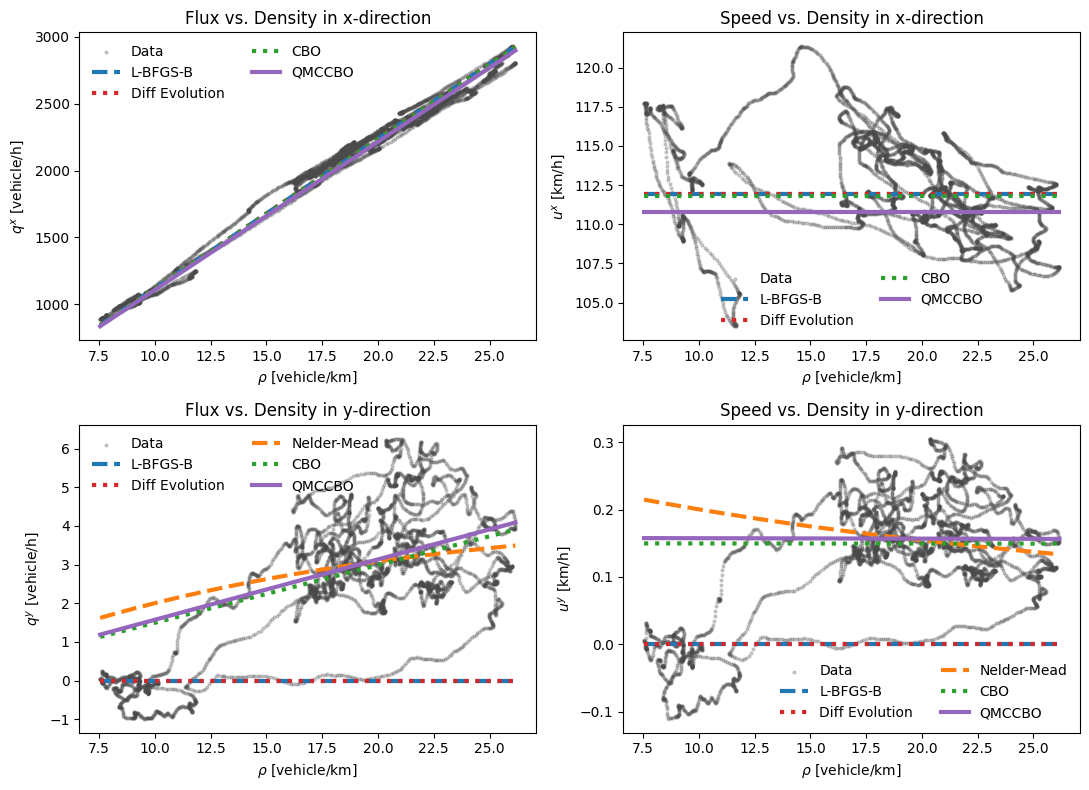

In [46]:
# plotting fundamental diagrams with fitted models
data_color = "#4a4a4a"

lw_main = 3
lw_other = 3
alpha_data = 0.25

fig, ax = plt.subplots(2, 2, figsize=(11,8))

# Flux x - directtion
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0,0].plot(rho_plot, qx_fit_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[0,0].plot(rho_plot, qx_fit_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
# ax[0,0].plot(rho_plot, qx_fit_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[0,0].plot(rho_plot, qx_fit_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[0,0].plot(rho_plot, qx_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")
ax[0,0].legend(fontsize=10, ncol=2, frameon=False)


# Speed x-dircetion
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0,1].plot(rho_plot, u_fit_x_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[0,1].plot(rho_plot, u_fit_x_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
# ax[0,1].plot(rho_plot, u_fit_x_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[0,1].plot(rho_plot, u_fit_x_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[0,1].plot(rho_plot, u_fit_x_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")
ax[0,1].legend(fontsize=10, ncol=2, frameon=False)

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1,0].plot(rho_plot, qy_fit_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[1,0].plot(rho_plot, qy_fit_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[1,0].plot(rho_plot, qy_fit_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[1,0].plot(rho_plot, qy_fit_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[1,0].plot(rho_plot, qy_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")
ax[1,0].legend(fontsize=10, ncol=2, frameon=False)

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1,1].plot(rho_plot, u_fit_y_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[1,1].plot(rho_plot, u_fit_y_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[1,1].plot(rho_plot, u_fit_y_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[1,1].plot(rho_plot, u_fit_y_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[1,1].plot(rho_plot, u_fit_y_QMCCBO, color="#9467bd",linewidth=lw_other, label="QMCCBO")
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")
ax[1,1].legend(fontsize=10, ncol=2, frameon=False)

plt.tight_layout()
plt.savefig("images/fundamental_diagrams_comparison_onramp.png", dpi=300, bbox_inches="tight")
plt.show()

In [44]:
qx_fit_de_at_data = qx_model_numpy(rho_data, alpha_x_de, lambda_x_de, p_x_de)
qx_fit_simplex_at_data = qx_model_numpy(rho_data, alpha_x_simplex, lambda_x_simplex, p_x_simplex)
qx_fit_lbfgs_at_data = qx_model_numpy(rho_data, alpha_x_lbfgs, lambda_x_lbfgs, p_x_lbfgs)
qx_fit_CBO_at_data = qx_model_numpy(rho_data, alpha_x_CBO, lambda_x_CBO, p_x_CBO)
qx_fit_QMCCBO_at_data = qx_model_numpy(rho_data, alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO)

err_qx_de = np.linalg.norm(qx_data - qx_fit_de_at_data) / np.linalg.norm(qx_data)
err_qx_simplex = np.linalg.norm(qx_data - qx_fit_simplex_at_data) / np.linalg.norm(qx_data)
err_qx_lbfgs = np.linalg.norm(qx_data - qx_fit_lbfgs_at_data) / np.linalg.norm(qx_data)
err_qx_CBO = np.linalg.norm(qx_data - qx_fit_CBO_at_data) / np.linalg.norm(qx_data)
err_qx_QMCCBO = np.linalg.norm(qx_data - qx_fit_QMCCBO_at_data) / np.linalg.norm(qx_data)

print("Relative L2-errors for qx:\n")

print(f"Differential Evolution : {err_qx_de:.6e}    | time = {time_x_de:.2f} s")
print(f"Nelder-Mead            : {err_qx_simplex:.6e}    | time = {time_x_simplex:.2f} s")
print(f"L-BFGS-B               : {err_qx_lbfgs:.6e}    | time = {time_x_lbfgs:.2f} s")
print(f"CBO                    : {err_qx_CBO:.6e}    | time = {time_x_CBO:.2f} s")
print(f"QMCCBO                 : {err_qx_QMCCBO:.6e}    | time = {time_x_QMCCBO:.2f} s")

Relative L2-errors for qx:

Differential Evolution : 2.564626e-02    | time = 1.23 s
Nelder-Mead            : 1.000000e+00    | time = 0.02 s
L-BFGS-B               : 2.564709e-02    | time = 0.21 s
CBO                    : 2.567333e-02    | time = 5.78 s
QMCCBO                 : 2.763393e-02    | time = 5.44 s


In [45]:
qy_fit_de_at_data = qy_model_numpy(rho_data, alpha_y_de, lambda_y_de, p_y_de)
qy_fit_simplex_at_data = qy_model_numpy(rho_data, alpha_y_simplex, lambda_y_simplex, p_y_simplex)
qy_fit_lbfgs_at_data = qy_model_numpy(rho_data, alpha_y_lbfgs, lambda_y_lbfgs, p_y_lbfgs)
qy_fit_CBO_at_data = qy_model_numpy(rho_data, alpha_y_CBO, lambda_y_CBO, p_y_CBO)
qy_fit_QMCCBO_at_data = qy_model_numpy(rho_data, alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO)

err_qy_de = np.linalg.norm(qy_data - qy_fit_de_at_data) / np.linalg.norm(qy_data)
err_qy_simplex = np.linalg.norm(qy_data - qy_fit_simplex_at_data) / np.linalg.norm(qy_data)
err_qy_lbfgs = np.linalg.norm(qy_data - qy_fit_lbfgs_at_data) / np.linalg.norm(qy_data)
err_qy_CBO = np.linalg.norm(qy_data - qy_fit_CBO_at_data) / np.linalg.norm(qy_data)
err_qy_QMCCBO = np.linalg.norm(qy_data - qy_fit_QMCCBO_at_data) / np.linalg.norm(qy_data)

print("Relative L2-errors for qy:\n")

print(f"Differential Evolution : {err_qy_de:.6e}    | time = {time_y_de:.2f} s")
print(f"Nelder-Mead            : {err_qy_simplex:.6e}    | time = {time_y_simplex:.2f} s")
print(f"L-BFGS-B               : {err_qy_lbfgs:.6e}    | time = {time_y_lbfgs:.2f} s")
print(f"CBO                    : {err_qy_CBO:.6e}    | time = {time_y_CBO:.2f} s")
print(f"QMCCBO                 : {err_qy_QMCCBO:.6e}    | time = {time_y_QMCCBO:.2f} s")

Relative L2-errors for qy:

Differential Evolution : 9.999521e-01    | time = 0.16 s
Nelder-Mead            : 4.253369e-01    | time = 0.14 s
L-BFGS-B               : 1.000003e+00    | time = 0.09 s
CBO                    : 3.996458e-01    | time = 5.57 s
QMCCBO                 : 3.977069e-01    | time = 5.41 s


### Monte-Carlo approximation of error

In [ ]:
# define function, that runs all stochastic optimization algorithms
def run_all_methods_once():

    # L-BFGS-B
    ax_lb, lx_lb, px_lb = minimize(objective_x_numpy, x0=[10,10,10], method="L-BFGS-B", bounds=[(-500,500)]*3, options={"maxiter": 400}).x
    ay_lb, ly_lb, py_lb = minimize(objective_y_numpy, x0=[-10,-10,-10], method="L-BFGS-B", bounds=[(-500,500)]*3, options={"maxiter": 400}).x

    # Differential Evolution
    ax_de, lx_de, px_de = differential_evolution(objective_x_numpy, bounds=[(-500,500)]*3, maxiter=22).x
    ay_de, ly_de, py_de = differential_evolution(objective_y_numpy, bounds=[(-500,500)]*3, maxiter=22).x

    # CBO
    res_x_cbo = CBO.minimize(
        objective_x_torch, dimensionality, 2**n_particles, initial_distribution, dt, l, sigma, 
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
    res_y_cbo = CBO.minimize(
        objective_x_torch, dimensionality, 2**n_particles, initial_distribution, dt, l, sigma, 
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
    ax_cbo, lx_cbo, px_cbo = res_x_cbo.numpy()
    ay_cbo, ly_cbo, py_cbo = res_y_cbo.numpy()


    # errors x-direction
    qx_de = np.linalg.norm(qx_data - qx_model_numpy(rho_data, ax_de, lx_de, px_de)) / np.linalg.norm(qx_data)
    qx_lb = np.linalg.norm(qx_data - qx_model_numpy(rho_data, ax_lb, lx_lb, px_lb)) / np.linalg.norm(qx_data)
    qx_cbo = np.linalg.norm(qx_data - qx_model_numpy(rho_data, ax_cbo, lx_cbo, px_cbo)) / np.linalg.norm(qx_data)

    # errors y-direction
    qy_de = np.linalg.norm(qy_data - qy_model_numpy(rho_data, ay_de, ly_de, py_de)) / np.linalg.norm(qy_data)
    qy_lb = np.linalg.norm(qy_data - qy_model_numpy(rho_data, ay_lb, ly_lb, py_lb)) / np.linalg.norm(qy_data)
    qy_cbo = np.linalg.norm(qy_data - qy_model_numpy(rho_data, ay_cbo, ly_cbo, py_cbo)) / np.linalg.norm(qy_data)

    return {
        "qx": [qx_de, qx_lb, qx_cbo],
        "qy": [qy_de, qy_lb, qy_cbo],
    }


In [18]:
n_mc = 1000

errors_x = []
errors_y = []

for i in range(n_mc):
    res = run_all_methods_once()
    errors_x.append(res["qx"])
    errors_y.append(res["qy"])

errors_x = np.array(errors_x)
errors_y = np.array(errors_y)

In [37]:
print("\nMean Relative L2-errors (Monte Carlo):\n")

# Differential Evolution
mean_x = errors_x[:, 0].mean()
std_x  = errors_x[:, 0].std()
mean_y = errors_y[:, 0].mean()
std_y  = errors_y[:, 0].std()
print(f"{'Diff Evo':<12} | x: {mean_x:.4e} ± {std_x:.2e}   | y: {mean_y:.4e} ± {std_y:.2e}")

# Nelder-Mead (deterministic)
print(f"{'Nelder-Mead':<12} | "
      f"x: {err_qx_simplex:.4e} ± {0.0:.2e}   | "
      f"y: {err_qy_simplex:.4e} ± {0.0:.2e}")

# L-BFGS-B
mean_x = errors_x[:, 1].mean()
std_x  = errors_x[:, 1].std()
mean_y = errors_y[:, 1].mean()
std_y  = errors_y[:, 1].std()
print(f"{'L-BFGS-B':<12} | x: {mean_x:.4e} ± {std_x:.2e}   | y: {mean_y:.4e} ± {std_y:.2e}")

# CBO
mean_x = errors_x[:, 2].mean()
std_x  = errors_x[:, 2].std()
mean_y = errors_y[:, 2].mean()
std_y  = errors_y[:, 2].std()
print(f"{'CBO':<12} | x: {mean_x:.4e} ± {std_x:.2e}   | y: {mean_y:.4e} ± {std_y:.2e}")

# QMCCBO (deterministic)
print(f"{'QMCCBO':<12} | "
      f"x: {err_qx_QMCCBO:.4e} ± {0.0:.2e}   | "
      f"y: {err_qy_QMCCBO:.4e} ± {0.0:.2e}")


Mean Relative L2-errors (Monte Carlo):

Diff Evo     | x: 6.0268e-01 ± 4.25e-01   | y: 6.7169e-01 ± 3.69e-01
Nelder-Mead  | x: 5.6497e-02 ± 0.00e+00   | y: 1.8670e-01 ± 0.00e+00
L-BFGS-B     | x: 5.7622e-02 ± 2.08e-17   | y: 1.8639e-01 ± 2.78e-17
CBO          | x: 1.3972e-01 ± 1.90e-01   | y: 3.2221e+02 ± 7.50e+01
QMCCBO       | x: 6.9190e-02 ± 0.00e+00   | y: 2.3901e-01 ± 0.00e+00


### Plots for visualizations

In [22]:
qx_fit_QMCCBO = qx_model_numpy(rho_plot, alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO)
qy_fit_QMCCBO = qy_model_numpy(rho_plot, alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO)
u_fit_x_QMCCBO = qx_fit_QMCCBO / np.maximum(rho_plot, 1e-6)
u_fit_y_QMCCBO = qy_fit_QMCCBO / np.maximum(rho_plot, 1e-6)
rho_plot = np.linspace(rho_data.min(), rho_data.max(), 1000)
qx_fit_QMCCBO_at_data = qx_model_numpy(rho_data, alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO)
err_qx_QMCCBO = np.linalg.norm(qx_data - qx_fit_QMCCBO_at_data) / np.linalg.norm(qx_data)
qy_fit_QMCCBO_at_data = qy_model_numpy(rho_data, alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO)
err_qy_QMCCBO = np.linalg.norm(qy_data - qy_fit_QMCCBO_at_data) / np.linalg.norm(qy_data)

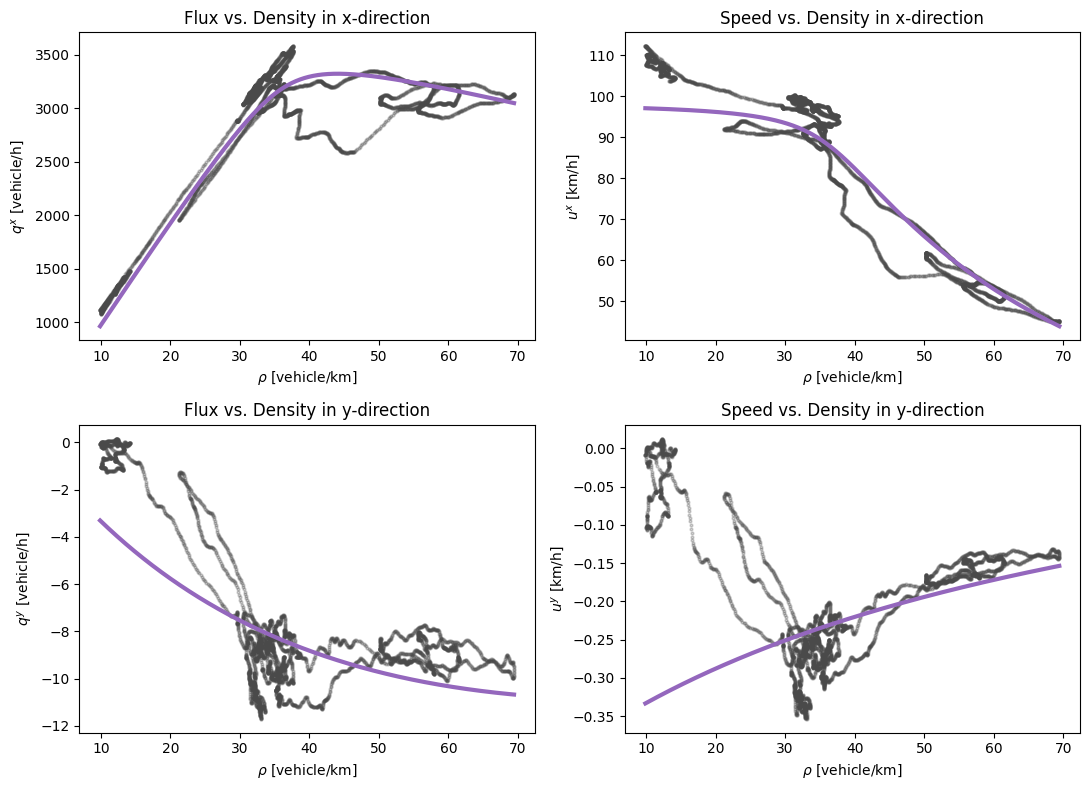

In [23]:
# plotting fundamental diagrams with fitted models
data_color = "#4a4a4a"

lw_main = 3
lw_other = 3
alpha_data = 0.25

fig, ax = plt.subplots(2, 2, figsize=(11,8))

# Flux x - directtion
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0,0].plot(rho_plot, qx_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")

# Speed x-dircetion
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0,1].plot(rho_plot, u_fit_x_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1,0].plot(rho_plot, qy_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1,1].plot(rho_plot, u_fit_y_QMCCBO, color="#9467bd",linewidth=lw_other, label="QMCCBO")
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")

plt.tight_layout()
plt.show()